In [32]:
import pandas as pd
import numpy as np

In [3]:
churn_data = pd.read_csv('/content/Churn_Modelling.csv')

In [4]:
churn_data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [7]:
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
churn_data.shape

(10000, 14)

In [5]:
churn_data.nunique()

RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

**Identify numerical and categorical features**

In [9]:
# Identify numerical columns(features)

numerical_columns = churn_data.select_dtypes(include='number').columns.tolist()
numerical_columns

['RowNumber',
 'CustomerId',
 'CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [10]:
# Identify categorical columns(features)
cat_columns = churn_data.select_dtypes(include='object').columns.tolist()
cat_columns

['Surname', 'Geography', 'Gender']

**Preprocessing the dataset**

In [12]:
# Convert categorical variables into numerical variables
from sklearn.preprocessing import LabelEncoder

churn_data["Geography"] = LabelEncoder().fit_transform(churn_data["Geography"])
churn_data["Gender"] = LabelEncoder().fit_transform(churn_data["Gender"])

In [22]:
# Dropping irrelevant columns such as "RowNumber," "CustomerId," and "Surname" to focus on the relevant features.

new_data = churn_data.drop(["RowNumber","CustomerId","Surname"], axis = 1)

In [23]:
new_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,0,0,42,2,0.00,1,1,1,101348.88,1
1,608,2,0,41,1,83807.86,1,0,1,112542.58,0
2,502,0,0,42,8,159660.80,3,1,0,113931.57,1
3,699,0,0,39,1,0.00,2,0,0,93826.63,0
4,850,2,0,43,2,125510.82,1,1,1,79084.10,0


<Axes: >

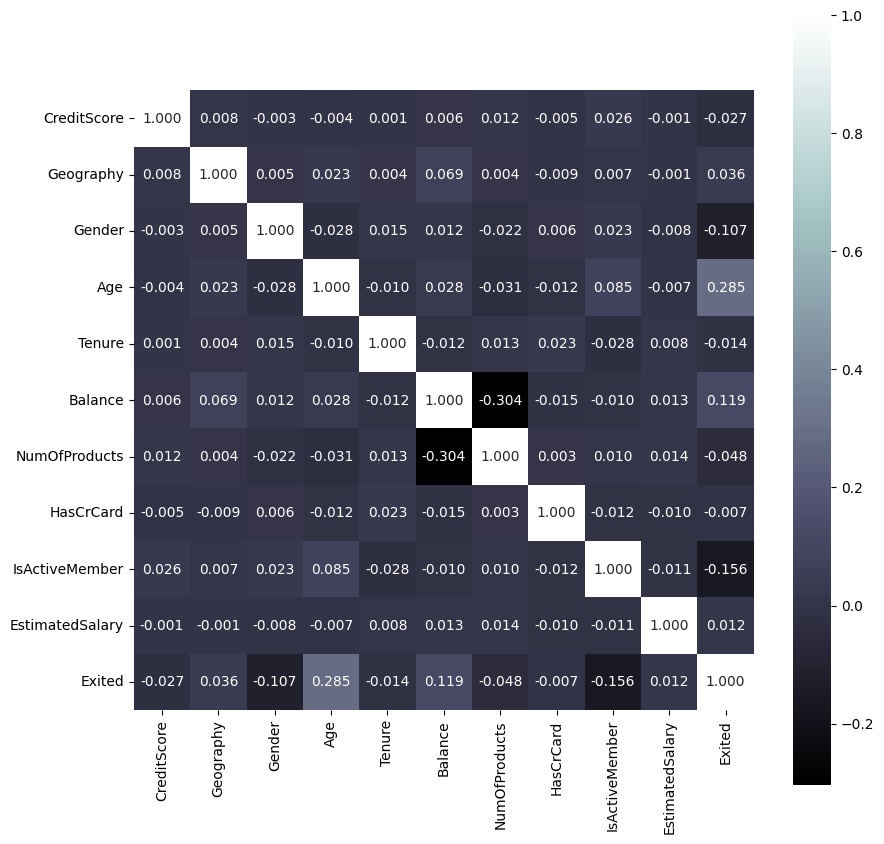

In [24]:
# A correlation analysis between the dataset's features
# Identifing relationships and dependencies among variables.

import matplotlib.pyplot as plt
import seaborn as sns

corr = new_data.corr()
plt.figure(figsize=(10,10))
sns.heatmap(corr, cbar=True, square= True, fmt='.3f', annot=True, annot_kws={'size':10}, cmap='bone')

In [ ]:
x = new_churn_data.loc[:,["CreditScore","Geography","Gender","Age","Tenure","Balance","NumOfProducts","IsActiveMember","EstimatedSalary"]].values
y = new_churn_data.iloc[:,-1]

In [27]:
# based on the correlation table to have high performance,
# I choose "HasCrCard" to drop from the dataset as it had a weak correlation (-0.007) with the target variable.
data = new_data.drop(["HasCrCard"], axis = 1)
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,IsActiveMember,EstimatedSalary,Exited
0,619,0,0,42,2,0.00,1,1,101348.88,1
1,608,2,0,41,1,83807.86,1,1,112542.58,0
2,502,0,0,42,8,159660.80,3,0,113931.57,1
3,699,0,0,39,1,0.00,2,0,93826.63,0
4,850,2,0,43,2,125510.82,1,1,79084.10,0


In [28]:
x = data.loc[:,["CreditScore","Geography","Gender","Age","Tenure","Balance","NumOfProducts","IsActiveMember","EstimatedSalary"]].values
y = data.iloc[:,-1]

In [29]:
print(x.shape)
print(y.shape)

(10000, 9)
(10000,)


In [43]:
data.to_csv('churn_data.csv')